<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/06_ten_day_horizon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 - 10-day horizon

Basel market risk uses a 99% VaR over 10 days. Two ways to get it: scale the 1-day VaR by sqrt(10), or simulate 10-day paths where the vol moves (GJR-GARCH with skewed-t shocks, the best 1-day model of 02). Tested on non-overlapping 10-day periods, so ~576 periods and only ~6 breaches expected: the tests have little power here. Takes ~3 min.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from risk import *
plt.style.use("quant.mplstyle")

prices = pd.concat({"spx": load_close("../black-scholes-sp500/data/sp500.csv"),
                    "aapl": load_close("data/aapl.csv")}, axis=1).dropna()
rets = np.log(prices).diff().dropna()
port = np.log1p((np.exp(rets) - 1) @ np.array([0.5, 0.5]))
names = {"normal": "normal x sqrt10", "hist": "historical x sqrt10", "hist10": "historical 10-day returns",
         "sqrt": "GJR skewed-t x sqrt10", "mc": "GJR skewed-t, 10-day paths"}

def summary(bt):
    print(len(bt), "periods, expected", round(0.01 * len(bt), 1), "breaches")
    for m in names:
        breach = bt["ret"] < -bt[f"var_{m}"]
        ratio = (-bt["ret"][breach]).mean() / bt[f"es_{m}"][breach].mean()
        print(f"{names[m]:27s} {breach.sum():3d} ({100*breach.mean():.2f}%)  kupiec p={kupiec(breach.values)[1]:.3f}  "
              f"christoffersen p={christoffersen(breach.values)[1]:.3f}  loss/ES={ratio:.2f}  avg VaR {100*bt[f'var_{m}'].mean():.1f}%")

In [3]:
bt = backtest_10d(rets.spx)
summary(bt)
# S&P 500: the 10-day paths give 6 breaches for 5.8 expected, the sqrt(10) versions 9 (normal and GJR) 
# normal x sqrt10 and the historical 10-day returns have their breaches in clusters (christoffersen < 0.01)
# historical x sqrt10 passes but by being high all the time (avg VaR 10.6%)
# with ~6 breaches expected kupiec can't reject much: 9 breaches still gives p = 0.21

576 periods, expected 5.8 breaches
normal x sqrt10               9 (1.56%)  kupiec p=0.210  christoffersen p=0.005  loss/ES=1.38  avg VaR 8.3%
historical x sqrt10           7 (1.22%)  kupiec p=0.615  christoffersen p=0.678  loss/ES=0.93  avg VaR 10.6%
historical 10-day returns    10 (1.74%)  kupiec p=0.108  christoffersen p=0.009  loss/ES=1.09  avg VaR 10.1%
GJR skewed-t x sqrt10         9 (1.56%)  kupiec p=0.210  christoffersen p=0.593  loss/ES=1.13  avg VaR 8.4%
GJR skewed-t, 10-day paths    6 (1.04%)  kupiec p=0.920  christoffersen p=0.722  loss/ES=0.90  avg VaR 10.0%


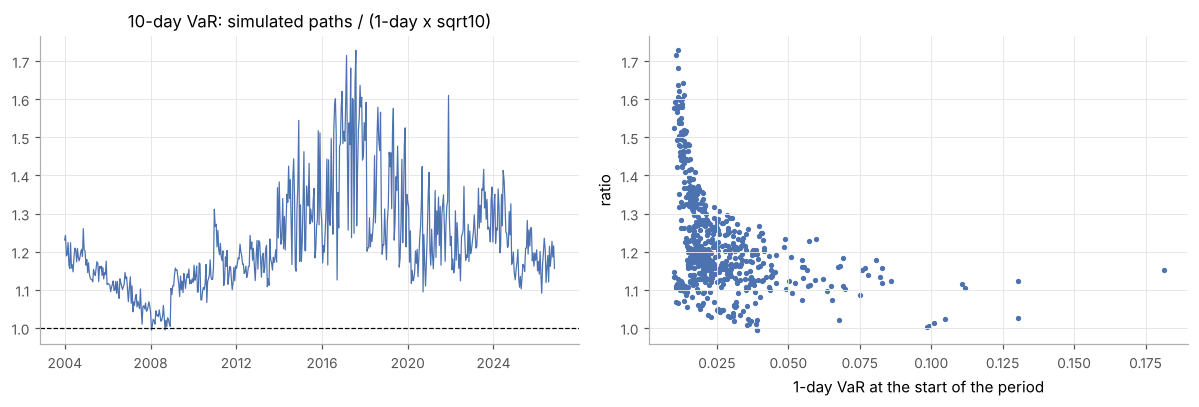

ratio mean 1.224  min 0.994  max 1.728  corr with the start vol -0.42


In [4]:
ratio = bt["var_mc"] / bt["var_sqrt"]
vol1 = bt["var_sqrt"] / np.sqrt(10)   # 1-day GJR VaR, follows the current vol
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ratio, lw=0.8)
ax[0].axhline(1, color="k", ls="--", lw=0.8)
ax[0].set_title("10-day VaR: simulated paths / (1-day x sqrt10)")
ax[1].scatter(vol1, ratio, s=6)
ax[1].set_xlabel("1-day VaR at the start of the period"); ax[1].set_ylabel("ratio")
plt.tight_layout(); plt.show()
print("ratio mean", round(ratio.mean(), 3), " min", round(ratio.min(), 3), " max", round(ratio.max(), 3),
      " corr with the start vol", round(np.corrcoef(ratio, vol1)[0, 1], 2))
# the simulated 10-day VaR is 22% above the sqrt(10) rule on average, and below it only once (0.994)
# biggest gap when the market is calm (up to 1.7 in 2017): the vol tends to go back up to its long-run level
# during the 10 days, and with GJR every bad day raises the vol of the next ones, so bad 10-day periods are worse
# than sqrt(10) says. when the vol is already high (2008) the gap shrinks to 1.0-1.15: it is expected to come down

In [5]:
bt_p = backtest_10d(port)
summary(bt_p)
ratio_p = bt_p["var_mc"] / bt_p["var_sqrt"]
print("ratio mean", round(ratio_p.mean(), 3))
# portfolio: here GJR skewed-t x sqrt10 is the one right on target (6 breaches), the paths are on the safe side
# (4 breaches, VaR 12% higher). normal x sqrt10 has 13 breaches, rejected
# historical x sqrt10 only 3 breaches: very conservative (avg VaR 12.5%)

576 periods, expected 5.8 breaches
normal x sqrt10              13 (2.26%)  kupiec p=0.009  christoffersen p=0.029  loss/ES=1.13  avg VaR 10.3%
historical x sqrt10           3 (0.52%)  kupiec p=0.203  christoffersen p=0.859  loss/ES=1.13  avg VaR 12.5%
historical 10-day returns    11 (1.91%)  kupiec p=0.051  christoffersen p=0.198  loss/ES=1.02  avg VaR 11.9%
GJR skewed-t x sqrt10         6 (1.04%)  kupiec p=0.920  christoffersen p=0.722  loss/ES=1.01  avg VaR 10.4%
GJR skewed-t, 10-day paths    4 (0.69%)  kupiec p=0.435  christoffersen p=0.813  loss/ES=1.02  avg VaR 11.5%
ratio mean 1.121
